
 TRAVELLING SALESMAN USING ACO
1. Generate Cities
2. Display Distance Matrix
3. Run ACO
4. Display Best Route
5. Display Convergence Graph
6. Exit

Enter your choice: 1

Cities generated successfully!
City 0: (37.45, 95.07)
City 1: (73.20, 59.87)
City 2: (15.60, 15.60)
City 3: (5.81, 86.62)
City 4: (60.11, 70.81)
City 5: (2.06, 96.99)
City 6: (83.24, 21.23)
City 7: (18.18, 18.34)
City 8: (30.42, 52.48)
City 9: (43.19, 29.12)

 TRAVELLING SALESMAN USING ACO
1. Generate Cities
2. Display Distance Matrix
3. Run ACO
4. Display Best Route
5. Display Convergence Graph
6. Exit

Enter your choice: 2

Distance Matrix:
[[  0.    50.17  82.42  32.76  33.2   35.45  86.88  79.11  43.17  66.2 ]
 [ 50.17   0.    72.64  72.51  17.06  80.25  39.92  68.93  43.41  42.96]
 [ 82.42  72.64   0.    71.69  70.92  82.51  67.88   3.76  39.74  30.73]
 [ 32.76  72.51  71.69   0.    56.56  11.03 101.35  69.39  42.09  68.58]
 [ 33.2   17.06  70.92  56.56   0.    63.68  54.71  67.16  34.89  44.99]
 [ 35.45  80.25  

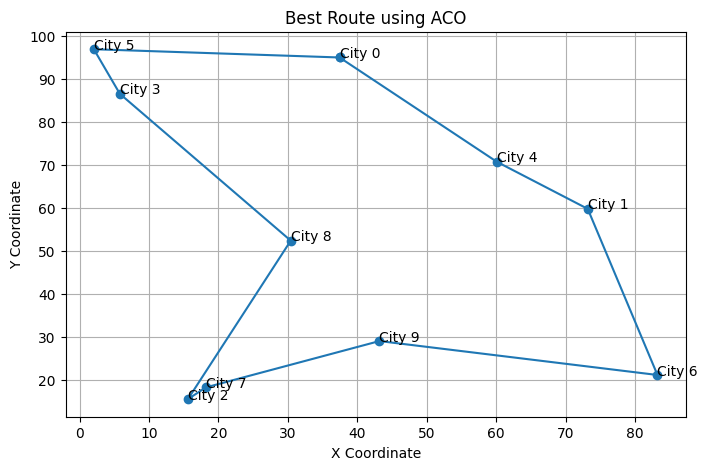


 TRAVELLING SALESMAN USING ACO
1. Generate Cities
2. Display Distance Matrix
3. Run ACO
4. Display Best Route
5. Display Convergence Graph
6. Exit

Enter your choice: 5


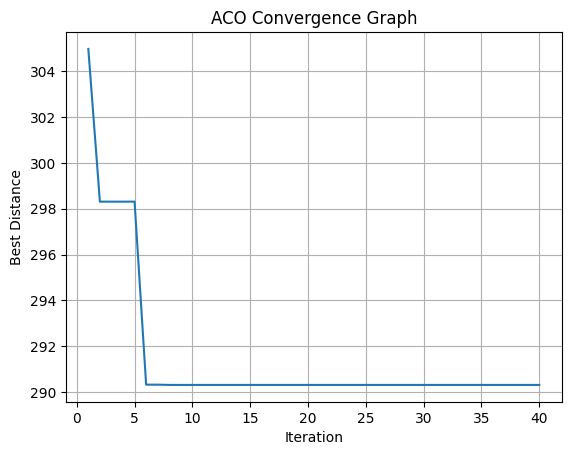


 TRAVELLING SALESMAN USING ACO
1. Generate Cities
2. Display Distance Matrix
3. Run ACO
4. Display Best Route
5. Display Convergence Graph
6. Exit

Enter your choice: 6
Exiting Program!


In [2]:

import numpy as np
import matplotlib.pyplot as plt

# =====================================
# GLOBAL VARIABLES
# =====================================

city_coords = None
dist_matrix = None
pheromone = None

best_path = None
best_distance = float('inf')
history = []

n_cities = 10

n_ants = 20
n_best = 5
n_iterations = 40

alpha = 1.0
beta = 3.0
decay = 0.1


# =====================================
# 1. GENERATE CITIES
# =====================================

def generate_cities():

    global city_coords, dist_matrix
    global pheromone, best_path, best_distance, history

    np.random.seed(42)

    city_coords = np.random.rand(n_cities, 2) * 100

    # Calculate distance matrix
    dist_matrix = np.sqrt(
        np.sum(
            (city_coords[:, np.newaxis, :] -
             city_coords[np.newaxis, :, :]) ** 2,
            axis=-1
        )
    )

    # Initialize pheromone
    pheromone = np.ones((n_cities, n_cities))

    best_path = None
    best_distance = float('inf')
    history = []

    print("\nCities generated successfully!")

    for i, (x, y) in enumerate(city_coords):
        print(f"City {i}: ({x:.2f}, {y:.2f})")


# =====================================
# 2. DISPLAY DISTANCE MATRIX
# =====================================

def display_distance():

    if dist_matrix is None:
        print("\nGenerate cities first!")
        return

    print("\nDistance Matrix:")
    print(np.round(dist_matrix, 2))


# =====================================
# 3. SELECT NEXT CITY
# =====================================

def select_next_city(current, visited):

    # Get pheromone and distance values
    p = pheromone[current].copy()
    d = dist_matrix[current].copy()

    # Ignore visited cities
    p[list(visited)] = 0

    # Calculate heuristic value
    h = np.zeros(n_cities)

    for city in range(n_cities):

        if city not in visited and d[city] > 0:
            h[city] = 1 / d[city]

    # Calculate probability
    probability = (p ** alpha) * (h ** beta)

    probability = probability / probability.sum()

    # Select next city
    return np.random.choice(n_cities, p=probability)


# =====================================
# 4. GENERATE PATH FOR ONE ANT
# =====================================

def generate_path():

    path = []
    visited = {0}

    current = 0

    for _ in range(n_cities - 1):

        next_city = select_next_city(current, visited)

        path.append((current, next_city))

        visited.add(next_city)
        current = next_city

    # Return to starting city
    path.append((current, 0))

    return path


# =====================================
# 5. CALCULATE PATH DISTANCE
# =====================================

def calculate_distance(path):

    distance = 0

    for start, end in path:
        distance += dist_matrix[start][end]

    return distance


# =====================================
# 6. RUN ACO ALGORITHM
# =====================================

def run_aco():

    global pheromone, best_path, best_distance, history

    if dist_matrix is None:
        print("\nGenerate cities first!")
        return

    best_path = None
    best_distance = float('inf')
    history = []

    pheromone = np.ones((n_cities, n_cities))

    for iteration in range(n_iterations):

        all_paths = []

        # Generate paths for all ants
        for ant in range(n_ants):

            path = generate_path()

            distance = calculate_distance(path)

            all_paths.append((path, distance))

        # Find best path in current iteration
        current_path, current_distance = min(
            all_paths, key=lambda x: x[1]
        )

        # Update overall best path
        if current_distance < best_distance:

            best_distance = current_distance
            best_path = current_path

        # Pheromone evaporation
        pheromone *= (1 - decay)

        # Sort paths by distance
        all_paths.sort(key=lambda x: x[1])

        # Deposit pheromone on best paths
        for path, distance in all_paths[:n_best]:

            for start, end in path:

                pheromone[start][end] += 1 / distance
                pheromone[end][start] += 1 / distance

        history.append(best_distance)

        print(
            f"Iteration {iteration + 1}: "
            f"Best Distance = {best_distance:.2f}"
        )

    print("\nACO Completed Successfully!")
    print("Minimum Distance:", round(best_distance, 2))


# =====================================
# 7. DISPLAY BEST ROUTE
# =====================================

def display_route():

    if best_path is None:
        print("\nRun ACO first!")
        return

    ordered_cities = [0]

    for start, end in best_path:
        ordered_cities.append(end)

    print("\nBest Route:")

    print(" -> ".join(
        f"City {city}" for city in ordered_cities
    ))

    print("Minimum Distance:", round(best_distance, 2))

    # Plot route
    plt.figure(figsize=(8, 5))

    plt.plot(
        city_coords[ordered_cities, 0],
        city_coords[ordered_cities, 1],
        'o-'
    )

    for i, (x, y) in enumerate(city_coords):
        plt.annotate(f"City {i}", (x, y))

    plt.title("Best Route using ACO")
    plt.xlabel("X Coordinate")
    plt.ylabel("Y Coordinate")
    plt.grid()
    plt.show()


# =====================================
# 8. DISPLAY CONVERGENCE GRAPH
# =====================================

def display_convergence():

    if not history:
        print("\nRun ACO first!")
        return

    plt.plot(range(1, len(history) + 1), history)

    plt.title("ACO Convergence Graph")
    plt.xlabel("Iteration")
    plt.ylabel("Best Distance")
    plt.grid()
    plt.show()


# =====================================
# 9. MAIN MENU
# =====================================

while True:

    print("\n================================")
    print(" TRAVELLING SALESMAN USING ACO")
    print("================================")

    print("1. Generate Cities")
    print("2. Display Distance Matrix")
    print("3. Run ACO")
    print("4. Display Best Route")
    print("5. Display Convergence Graph")
    print("6. Exit")

    choice = input("\nEnter your choice: ")

    if choice == "1":
        generate_cities()

    elif choice == "2":
        display_distance()

    elif choice == "3":
        run_aco()

    elif choice == "4":
        display_route()

    elif choice == "5":
        display_convergence()

    elif choice == "6":
        print("Exiting Program!")
        break

    else:
        print("Invalid choice!")
